Runs on **Google Colab** (Runtime → Change runtime type → T4 GPU) or **locally**.

### Setup (Colab or local)

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/sathyaa23/text-to-image-diffusion.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo = Path("/content/text-to-image-diffusion")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(repo / "requirements.txt")], check=True)
    os.chdir(repo)
else:
    # Walk up from wherever Jupyter was launched until we find the repo
    repo = Path.cwd().resolve()
    while not (repo / "src").is_dir() and repo != repo.parent:
        repo = repo.parent
    if not (repo / "src").is_dir():
        raise RuntimeError("Couldn't find the repo root (a folder containing src/).")

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Repo root:", repo, "| Colab:", IN_COLAB)

Repo root: /home/varun/Documents/Courses/Deep learning/text-to-image-diffusion | Colab: False


### Environment & config

In [2]:
from src.utils import REPO_ROOT, milestone_dir, get_device, environment_info

DEVICE, DTYPE = get_device()
ENV = environment_info(DEVICE, DTYPE)
ENV

{'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 3060 Laptop GPU',
 'dtype': 'torch.float16',
 'versions': {'python': '3.10.21',
  'torch': '2.14.0+cu130',
  'diffusers': '0.41.0',
  'transformers': '5.18.0'}}

In [3]:
OUT_DIR = milestone_dir("milestone2_conditioning")

MODEL_ID   = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # fallback: "sd-legacy/stable-diffusion-v1-5"
SEED       = 42
HEIGHT     = 512
WIDTH      = 512
NEG_PROMPT = "blurry, lowres, distorted, watermark, text"

print("Outputs:", OUT_DIR)

Outputs: /home/varun/Documents/Courses/Deep learning/text-to-image-diffusion/outputs/milestone2_conditioning


### Text encoder integration

In [4]:
from src.pipeline import load_text_encoder, tokenize, encode_prompt

tokenizer, text_encoder = load_text_encoder(MODEL_ID, DEVICE, DTYPE)

n_params = sum(p.numel() for p in text_encoder.parameters())
print(f"Text encoder: {type(text_encoder).__name__} | {n_params/1e6:.0f}M params")
print(f"Max tokens: {tokenizer.model_max_length} | hidden size: {text_encoder.config.hidden_size}")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Text encoder: CLIPTextModel | 123M params
Max tokens: 77 | hidden size: 768


In [5]:
# What the tokenizer actually does to a prompt
prompt = "a blue cube to the left of a yellow sphere on a white floor"
ids = tokenize(prompt, tokenizer).input_ids[0]

n_real = int((ids != tokenizer.pad_token_id).sum())   # tokens before padding
print(f"{n_real} real tokens (incl. start/end), padded to {len(ids)}")
print(tokenizer.convert_ids_to_tokens(ids[:n_real]))

15 real tokens (incl. start/end), padded to 77
['<|startoftext|>', 'a</w>', 'blue</w>', 'cube</w>', 'to</w>', 'the</w>', 'left</w>', 'of</w>', 'a</w>', 'yellow</w>', 'sphere</w>', 'on</w>', 'a</w>', 'white</w>', 'floor</w>']


In [6]:
# Conditional vs. unconditional embeddings: the two inputs CFG combines
cond   = encode_prompt(prompt, tokenizer, text_encoder)
uncond = encode_prompt(NEG_PROMPT, tokenizer, text_encoder)

print("cond  :", tuple(cond.shape),   cond.dtype)
print("uncond:", tuple(uncond.shape), uncond.dtype)

cond  : (1, 77, 768) torch.float16
uncond: (1, 77, 768) torch.float16


In [7]:
# Sanity check: does the encoder capture meaning?
# Uses CLIP's pooled (end-of-text) vector, which summarises the whole prompt.
import torch
import torch.nn.functional as F

probe = [
    "a red apple on a wooden table",
    "a green apple on a kitchen counter",
    "a cat and a dog sitting on a park bench",
]
with torch.no_grad():
    pooled = text_encoder(tokenize(probe, tokenizer).input_ids.to(DEVICE)).pooler_output.float()
sim = F.cosine_similarity(pooled[:, None], pooled[None, :], dim=-1)

for i, p in enumerate(probe):
    print(" ".join(f"{s:.2f}" for s in sim[i].tolist()), "|", p)

1.00 0.63 0.30 | a red apple on a wooden table
0.63 1.00 0.24 | a green apple on a kitchen counter
0.30 0.24 1.00 | a cat and a dog sitting on a park bench


### Diffusion components & denoising loop

In [8]:
from src.pipeline import load_diffusion_components, generate
from src.utils import make_generator

unet, vae, scheduler = load_diffusion_components(MODEL_ID, DEVICE, DTYPE)

print("UNet params:", f"{sum(p.numel() for p in unet.parameters())/1e6:.0f}M")
print("Scheduler  :", type(scheduler).__name__)
print("Training noise schedule:", scheduler.config.beta_schedule,
      f"| beta {scheduler.config.beta_start} → {scheduler.config.beta_end}",
      f"| {scheduler.config.num_train_timesteps} timesteps")

/home/varun/Anaconda/ENTER/envs/deeplearning/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


UNet params: 860M
Scheduler  : PNDMScheduler
Training noise schedule: scaled_linear | beta 0.00085 → 0.012 | 1000 timesteps


Mean pixel difference vs. M1: 0.20 (0–255 scale)


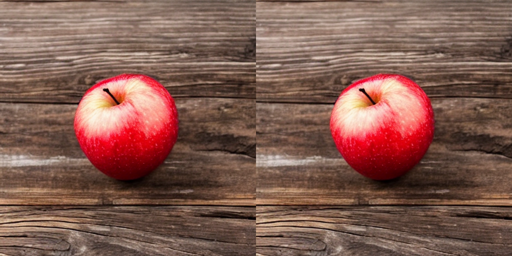

In [9]:
from PIL import Image
from IPython.display import display
import numpy as np 

img = generate(
    "a red apple on a wooden table",
    tokenizer, text_encoder, unet, vae, scheduler,
    negative_prompt=NEG_PROMPT,
    guidance_scale=7.5,
    num_steps=30,
    height=HEIGHT, width=WIDTH,
    generator=make_generator(SEED, DEVICE),
)

m1 = Image.open(REPO_ROOT / "outputs/milestone1_baseline/images/p1_simple_object.png").convert("RGB")
diff = np.abs(np.asarray(img, dtype=np.float32) - np.asarray(m1, dtype=np.float32)).mean()
print(f"Mean pixel difference vs. M1: {diff:.2f} (0–255 scale)")

side_by_side = Image.new("RGB", (WIDTH * 2, HEIGHT))
side_by_side.paste(img, (0, 0))
side_by_side.paste(m1, (WIDTH, 0))
display(side_by_side.resize((WIDTH, HEIGHT // 2)))

### Baseline conditional generation

In [10]:
import time
from src.utils import make_grid, save_run_log, write_gallery

PROMPTS = [
    ("p1_simple_object", "a red apple on a wooden table"),
    ("p2_multi_object",  "a cat and a dog sitting together on a park bench"),
    ("p3_spatial",       "a blue cube to the left of a yellow sphere on a white floor"),
    ("p4_stylistic",     "a mountain lake at sunrise, in the style of a watercolor painting"),
    ("p5_abstract",      "the feeling of nostalgia, surreal dreamlike digital art"),
]

BASE_GUIDANCE = 7.5
BASE_STEPS    = 30

RUNS = {}   # image path -> run metadata; every experiment adds to this

In [11]:
exp_dir = OUT_DIR / "baseline"
exp_dir.mkdir(exist_ok=True)
baseline_images = []

for tag, prompt in PROMPTS:
    start = time.time()
    img = generate(
        prompt, tokenizer, text_encoder, unet, vae, scheduler,
        negative_prompt=NEG_PROMPT,
        guidance_scale=BASE_GUIDANCE,
        num_steps=BASE_STEPS,
        height=HEIGHT, width=WIDTH,
        generator=make_generator(SEED, DEVICE),   # same seed per prompt
    )
    seconds = round(time.time() - start, 2)

    rel_path = f"baseline/{tag}.png"
    img.save(OUT_DIR / rel_path)
    baseline_images.append(img)

    RUNS[rel_path] = {
        "experiment": "baseline",
        "tag": tag,
        "prompt": prompt,
        "negative_prompt": NEG_PROMPT,
        "seed": SEED,
        "steps": BASE_STEPS,
        "guidance_scale": BASE_GUIDANCE,
        "scheduler": type(scheduler).__name__,
        "height": HEIGHT,
        "width": WIDTH,
        "seconds": seconds,
        "image": rel_path,
    }
    print(f"[{seconds:>5.1f}s] {tag}")

make_grid(baseline_images, cols=5).save(exp_dir / "grid.png")

save_run_log(OUT_DIR, ENV, RUNS, model_id=MODEL_ID)
write_gallery(OUT_DIR, RUNS, "Milestone 2 — Conditional generation")
print("Saved to", exp_dir)

[  4.4s] p1_simple_object
[  4.4s] p2_multi_object
[  4.4s] p3_spatial
[  4.4s] p4_stylistic
[  4.4s] p5_abstract
Saved to /home/varun/Documents/Courses/Deep learning/text-to-image-diffusion/outputs/milestone2_conditioning/baseline


### Classifier-free guidance sweep

In [12]:
from src.utils import add_caption

GUIDANCE_SCALES = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]

exp_dir = OUT_DIR / "guidance_sweep"
exp_dir.mkdir(exist_ok=True)
grid_cells = []

for tag, prompt in PROMPTS:
    for g in GUIDANCE_SCALES:
        start = time.time()
        img = generate(
            prompt, tokenizer, text_encoder, unet, vae, scheduler,
            negative_prompt=NEG_PROMPT,
            guidance_scale=g,
            num_steps=BASE_STEPS,
            height=HEIGHT, width=WIDTH,
            generator=make_generator(SEED, DEVICE),
        )
        seconds = round(time.time() - start, 2)

        rel_path = f"guidance_sweep/{tag}_cfg{g}.png"
        img.save(OUT_DIR / rel_path)
        grid_cells.append(add_caption(img, f"{tag} · cfg {g}"))

        RUNS[rel_path] = {
            "experiment": "guidance_sweep",
            "tag": f"{tag}_cfg{g}",
            "prompt": prompt,
            "negative_prompt": NEG_PROMPT,
            "seed": SEED,
            "steps": BASE_STEPS,
            "guidance_scale": g,
            "scheduler": type(scheduler).__name__,
            "height": HEIGHT,
            "width": WIDTH,
            "seconds": seconds,
            "image": rel_path,
        }
    print(f"[done] {tag}")

guidance_grid = make_grid(grid_cells, cols=len(GUIDANCE_SCALES))
guidance_grid.save(exp_dir / "grid.png")

save_run_log(OUT_DIR, ENV, RUNS, model_id=MODEL_ID)
write_gallery(OUT_DIR, RUNS, "Milestone 2 — Conditional generation")
print("Saved to", exp_dir)

[done] p1_simple_object
[done] p2_multi_object
[done] p3_spatial
[done] p4_stylistic
[done] p5_abstract
Saved to /home/varun/Documents/Courses/Deep learning/text-to-image-diffusion/outputs/milestone2_conditioning/guidance_sweep


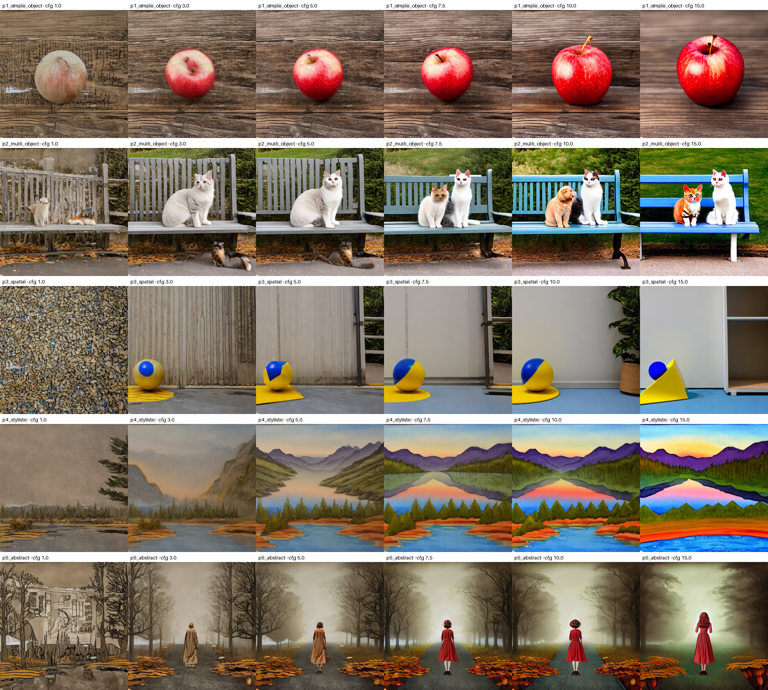

In [13]:
display(guidance_grid.resize((guidance_grid.width // 4, guidance_grid.height // 4)))